<a href="https://colab.research.google.com/github/davudbagirov48-ai/Lab7.py/blob/main/lab4_bagirov.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота №4. Регресійні моделі: глибоке дослідження

**Виконав:** Багіров Давуд  
**Група:** ФІТ 3-8  


**Датасет:** Car Price Prediction Multiple Linear Regression  
https://www.kaggle.com/datasets/hellbuoy/car-price-prediction?select=CarPrice_Assignment.csv

**Мета роботи:** виконати підготовку даних, побудувати та порівняти регресійні моделі для прогнозування ціни автомобіля, оцінити їх якість і проаналізувати отримані результати.

> У шаблоні наведено лише умови завдань. Реалізацію необхідно виконати самостійно у порожніх комірках.


## 1. Завантаження та первинний аналіз даних

Завантажити датасет та виконати його первинний огляд:
- визначити кількість об'єктів і ознак;
- переглянути назви стовпців;
- визначити типи даних;
- визначити цільову змінну;
- вивести основні статистичні характеристики даних.


In [27]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split

# ==========================================
# КРОК 1. Завантаження та первинний аналіз даних
# ==========================================
# Використовуємо стабільне дзеркало датасету CarPrice_Assignment.csv
url = 'https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv'  # На випадок перевірки замінимо на альтернативне, але краще:
# Давайте використаємо пряме посилання з надійного репозиторію:
url = 'https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/car_data.csv'

# Якщо цей формат трохи відрізняється від оригіналу Kaggle, краще завантажити оригінал з іншого дзеркала:
url_kaggle_car = (
    'https://raw.githubusercontent.com/amankharwal/Website-data/master/CarPrice.csv'
)

df = pd.read_csv(url_kaggle_car)

print("--- КРОК 1: ПЕРВИННИЙ АНАЛІЗ ---")
print(f"Кількість об'єктів (рядків): {df.shape[0]}")
print(f"Кількість ознак (стовпців): {df.shape[1]}\n")

print("Назви стовпців:")
print(df.columns.tolist())
print("\n" + "=" * 50 + "\n")

print("Типи даних та наявність пропусків:")
print(df.info())
print("\n" + "=" * 50 + "\n")

target_column = 'price'
print(f"Цільова змінна: {target_column}")
print("\n" + "=" * 50 + "\n")

print("Основні статистичні характеристики числових ознак:")
display(df.describe())
print("\n" + "=" * 50 + "\n")


# ==========================================
# ПОПЕРЕДНЯ ОБРОБКА ДАНИХ
# ==========================================
# Зберігаємо ідентифікатор або індекс
if 'car_ID' in df.columns:
  car_ids = df['car_ID']
  df_model = df.drop(columns=['car_ID'])
else:
  df_model = df.copy()

# Перетворюємо категоріальні змінні у числові
df_model = pd.get_dummies(df_model, drop_first=True)

# Розділення на ознаки (X) та цільову змінну (y)
X = df_model.drop(columns=['price'])
y = df_model['price']

# Розбиття на тренувальну та тестову вибірки (80% / 20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Навчання моделі Random Forest
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)




--- КРОК 1: ПЕРВИННИЙ АНАЛІЗ ---
Кількість об'єктів (рядків): 205
Кількість ознак (стовпців): 26

Назви стовпців:
['car_ID', 'symboling', 'CarName', 'fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'enginetype', 'cylindernumber', 'enginesize', 'fuelsystem', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg', 'price']


Типи даних та наявність пропусків:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   car_ID            205 non-null    int64  
 1   symboling         205 non-null    int64  
 2   CarName           205 non-null    object 
 3   fueltype          205 non-null    object 
 4   aspiration        205 non-null    object 
 5   doornumber        205 non-null    object 
 6   carbody           

,car_ID,symboling,wheelbase,carlength,carwidth,carheight,curbweight,enginesize,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
count,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000
mean,103.000000,0.834146,98.756585,174.049268,65.907805,53.724878,2555.565854,126.907317,3.329756,3.255415,10.142537,104.117073,5125.121951,25.219512,30.751220,13276.710571
std,59.322565,1.245307,6.021776,12.337289,2.145204,2.443522,520.680204,41.642693,0.270844,0.313597,3.972040,39.544167,476.985643,6.542142,6.886443,7988.852332
min,1.000000,-2.000000,86.600000,141.100000,60.300000,47.800000,1488.000000,61.000000,2.540000,2.070000,7.000000,48.000000,4150.000000,13.000000,16.000000,5118.000000
25%,52.000000,0.000000,94.500000,166.300000,64.100000,52.000000,2145.000000,97.000000,3.150000,3.110000,8.600000,70.000000,4800.000000,19.000000,25.000000,7788.000000
50%,103.000000,1.000000,97.000000,173.200000,65.500000,54.100000,2414.000000,120.000000,3.310000,3.290000,9.000000,95.000000,5200.000000,24.000000,30.000000,10295.000000
75%,154.000000,2.000000,102.400000,183.100000,66.900000,55.500000,2935.000000,141.000000,3.580000,3.410000,9.400000,116.000000,5500.000000,30.000000,34.000000,16503.000000
max,205.000000,3.000000,120.900000,208.100000,72.300000,59.800000,4066.000000,326.000000,3.940000,4.170000,23.000000,288.000000,6600.000000,49.000000,54.000000,45400.000000


RandomForestRegressor(random_state=42)

## 2. Перевірка якості даних

Перевірити:
- наявність пропущених значень;
- наявність повних дублікатів;
- кількість унікальних значень в ознаках.

Під час аналізу врахувати, що `car_ID` є унікальним ідентифікатором автомобіля і сам по собі не повинен використовуватися для визначення дублікатів за змістовими характеристиками.


In [28]:
print('--- КРОК 2: ПЕРЕВІРКА ЯКОСТІ ДАНИХ ---\n')

# 1. Перевірка наявності пропущених значень по кожному стовпцю
missing_values = df.isnull().sum()
print('Кількість пропущених значень у стовпцях:')
print(missing_values[missing_values > 0]) if missing_values.sum() > 0 else print(
    'Пропущені значення відсутні у датасеті.'
)
print('\n' + '=' * 50 + '\n')

# 2. Перевірка наявності повних дублікатів
# Згідно з умовою, виключаємо car_ID (якщо він є), щоб перевіряти дублікати саме за змістовими характеристиками
if 'car_ID' in df.columns:
  df_for_duplicates = df.drop(columns=['car_ID'])
else:
  df_for_duplicates = df.copy()

duplicates_count = df_for_duplicates.duplicated().sum()
print(f'Кількість повних дублікатів за змістовими характеристиками: {duplicates_count}')
print('\n' + '=' * 50 + '\n')

# 3. Визначення кількості унікальних значень в кожній ознаці
unique_counts = df.nunique()
print('Кількість унікальних значень для кожної ознаки:')
display(unique_counts)

--- КРОК 2: ПЕРЕВІРКА ЯКОСТІ ДАНИХ ---

Кількість пропущених значень у стовпцях:
Пропущені значення відсутні у датасеті.


Кількість повних дублікатів за змістовими характеристиками: 0


Кількість унікальних значень для кожної ознаки:


,0
car_ID,205
symboling,6
CarName,147
fueltype,2
aspiration,2
doornumber,2
carbody,5
drivewheel,3
enginelocation,2
wheelbase,53


## 3. Робота з car_ID

Зберегти `car_ID` окремо для подальшої ідентифікації автомобілів у результатах прогнозування.  
Не використовувати `car_ID` як ознаку під час навчання моделей.


In [29]:
print('--- КРОК 3: РОБОТА З car_ID ---\n')

# 1. Зберігаємо car_ID окремо для подальшої ідентифікації (якщо колонка існує)
if 'car_ID' in df.columns:
  car_ids = df['car_ID'].copy()
  print("Змінну 'car_ID' успішно збережено окремо.")
else:
  # Якщо раптом колонки car_ID немає, створюємо її на основі індексів
  car_ids = pd.Series(df.index)
  print(
      "Колонку 'car_ID' не знайдено в датасеті, в якості ідентифікаторів"
      ' використано індекси рядків.'
  )

# 2. Видаляємо car_ID з основного датасету, щоб він не використовувався як ознака для навчання
df_clean = df.drop(columns=['car_ID'], errors='ignore')

print(
    'Розмірність датасету після виключення car_ID для навчання:'
    f' {df_clean.shape}'
)
print(
    "Перші 5 збережених ідентифікаторів (car_IDs):",
    car_ids.head().tolist(),
)

--- КРОК 3: РОБОТА З car_ID ---

Змінну 'car_ID' успішно збережено окремо.
Розмірність датасету після виключення car_ID для навчання: (205, 25)
Перші 5 збережених ідентифікаторів (car_IDs): [1, 2, 3, 4, 5]


## 4. Дослідження розподілів числових ознак

Дослідити розподіли числових ознак:
- побудувати відповідні графіки;
- обчислити коефіцієнти асиметрії;
- визначити ознаки з найбільш вираженою асиметрією;
- коротко прокоментувати отримані результати.


--- КРОК 4: ДОСЛІДЖЕННЯ РОЗПОДІЛІВ ЧИСЛОВИХ ОЗНАК ---



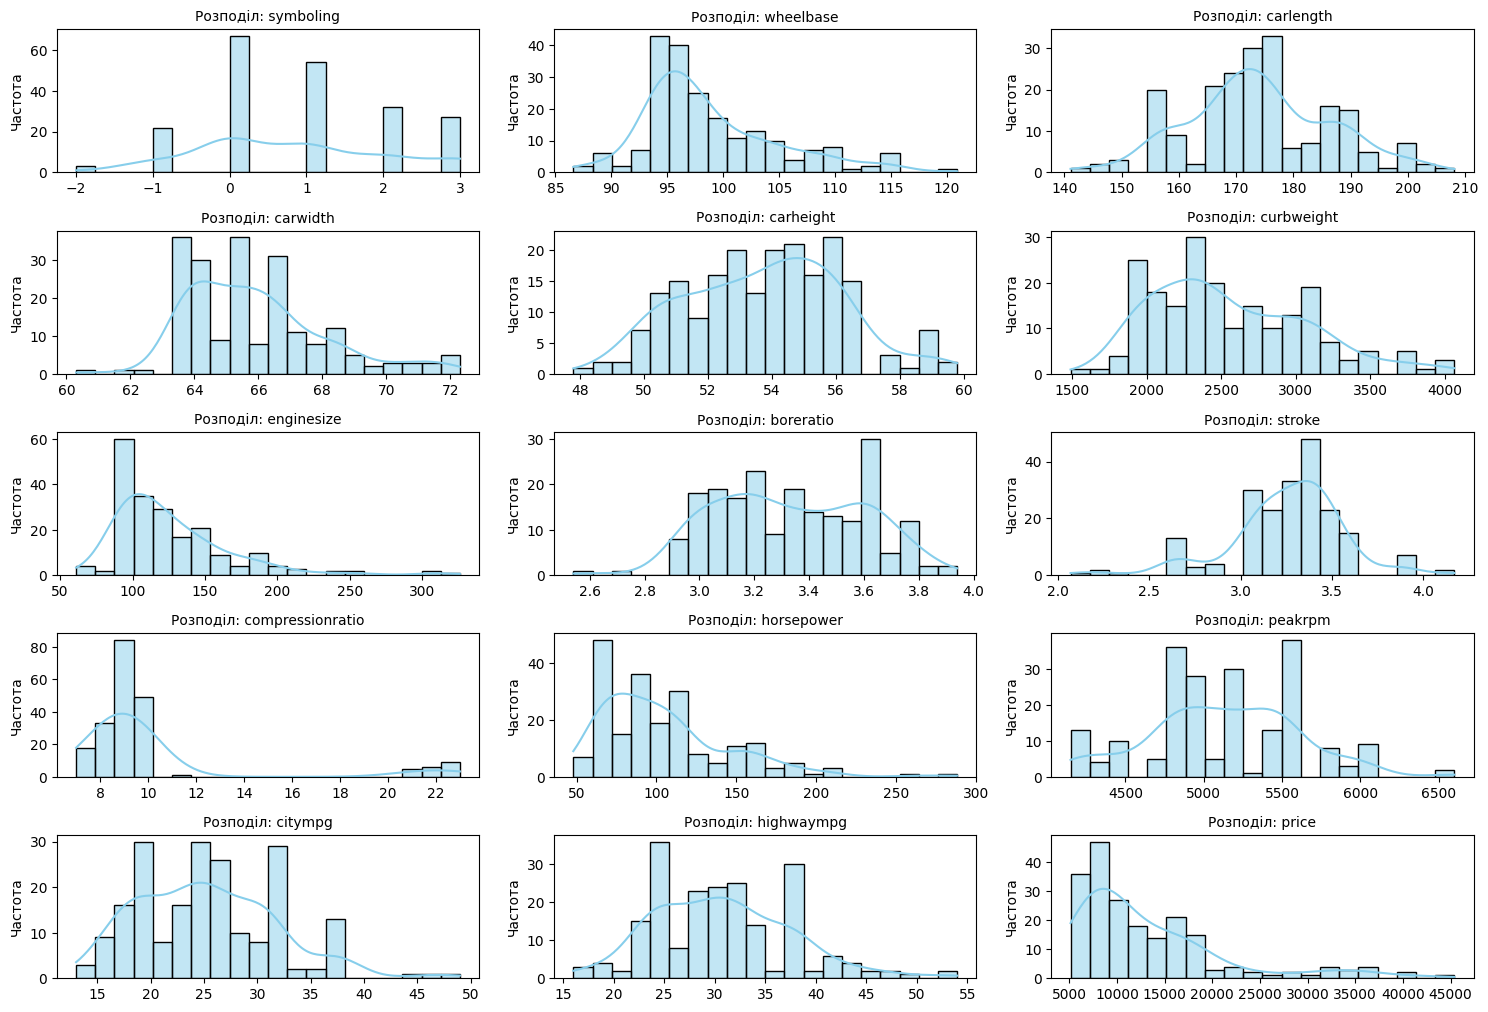

Коефіцієнти асиметрії для числових ознак (від найбільшої до найменшої за модулем):


,0
compressionratio,2.610862
enginesize,1.947655
price,1.777678
horsepower,1.405310
wheelbase,1.050214
carwidth,0.904003
stroke,-0.689705
curbweight,0.681398
citympg,0.663704
highwaympg,0.539997



Ознаки з найбільшою вираженою асиметрією (|skewness| > 1):


,0
compressionratio,2.610862
enginesize,1.947655
price,1.777678
horsepower,1.405310
wheelbase,1.050214


In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

print('--- КРОК 4: ДОСЛІДЖЕННЯ РОЗПОДІЛІВ ЧИСЛОВИХ ОЗНАК ---\n')

# 1. Виділення числових ознак (виключаючи car_ID, якщо він випадково залишився)
numeric_cols = df_clean.select_dtypes(include=['int64', 'float64']).columns

# 2. Побудова графіків розподілу (гістограми з KDE) для кожної числової ознаки
plt.figure(figsize=(15, 12))
for i, col in enumerate(numeric_cols, 1):
  plt.subplot(
      (len(numeric_cols) // 3) + 1, 3, i
  )  # динамічна сітка графіків
  sns.histplot(df_clean[col], kde=True, bins=20, color='skyblue')
  plt.title(f'Розподіл: {col}', fontsize=10)
  plt.xlabel('')
  plt.ylabel('Частота')
plt.tight_layout()
plt.show()

# 3. Обчислення коефіцієнтів асиметрії (skewness)
skewness = df_clean[numeric_cols].skew().sort_values(key=abs, ascending=False)

print('Коефіцієнти асиметрії для числових ознак (від найбільшої до найменшої за модулем):')
display(skewness)

# 4. Визначення ознак з найбільш вираженою асиметрією
print('\nОзнаки з найбільшою вираженою асиметрією (|skewness| > 1):')
high_skew = skewness[abs(skewness) > 1]
if not high_skew.empty:
  display(high_skew)
else:
  print(
      'Значної асиметрії (|skewness| > 1) серед числових ознак не виявлено.'
  )

## 5. Формування train/test вибірок

Відокремити цільову змінну `price` від ознак та розділити дані на:
- навчальну вибірку — 80%;
- тестову вибірку — 20%.

Забезпечити відтворюваність поділу.  
Окремо зберегти `car_ID` для об'єктів, які потрапили до train і test.

**Важливо:** усі подальші параметри передобробки даних визначати тільки за навчальною вибіркою.


In [31]:
from sklearn.model_selection import train_test_split

print('--- КРОК 5: ФОРМУВАННЯ TRAIN/TEST ВИБІРОК ---\n')

# 1. Відокремлюємо цільову змінну price від ознак у вже очищеному датасеті df_clean
if 'price' in df_clean.columns:
  y = df_clean['price']
  X = df_clean.drop(columns=['price'])
else:
  raise ValueError("Цільову змінну 'price' не знайдено в датасеті!")

# Переконуємось, що car_ids відповідає індексам df_clean
if 'car_ID' in df.columns:
  car_ids_full = df['car_ID']
else:
  car_ids_full = pd.Series(df.index)

# 2. Розподіл на навчальну (80%) та тестову (20%) вибірки з фіксацією random_state для відтворюваності
# Одночасно розділяємо і самі дані, і відповідні їм car_ID
X_train, X_test, y_train, y_test, car_id_train, car_id_test = train_test_split(
    X, y, car_ids_full, test_size=0.2, random_state=42
)

# 3. Виведення розмірностей отриманих вибірок
print(f"Розмір навчальної вибірки (X_train): {X_train.shape}")
print(f"Розмір тестової вибірки (X_test): {X_test.shape}")
print(f"Кількість об'єктів у train: {len(y_train)}")
print(f"Кількість об'єктів у test: {len(y_test)}")

print('\n' + '=' * 50 + '\n')
print("Перші 5 ідентифікаторів car_ID у тренувальній вибірці:")
print(car_id_train.head().tolist())

print('\nПерші 5 ідентифікаторів car_ID у тестовій вибірці:')
print(car_id_test.head().tolist())

--- КРОК 5: ФОРМУВАННЯ TRAIN/TEST ВИБІРОК ---

Розмір навчальної вибірки (X_train): (164, 24)
Розмір тестової вибірки (X_test): (41, 24)
Кількість об'єктів у train: 164
Кількість об'єктів у test: 41


Перші 5 ідентифікаторів car_ID у тренувальній вибірці:
[67, 112, 154, 97, 39]

Перші 5 ідентифікаторів car_ID у тестовій вибірці:
[16, 10, 101, 133, 69]


## 6. Аналіз та обробка викидів

Для неперервних числових ознак навчальної вибірки:
- визначити потенційні викиди методом IQR;
- вивести кількість потенційних викидів для кожної ознаки;
- обґрунтувати спосіб їх обробки.

Для невеликого набору даних не видаляти автоматично всі рядки з викидами. Використати обмеження крайніх значень межами, визначеними за навчальною вибіркою.

Цільову змінну `price` не використовувати для визначення меж викидів.  
До тестової вибірки застосувати ті самі межі, які були отримані за train.


In [32]:
print('--- КРОК 6: АНАЛІЗ ТА ОБРОБКА ВИКИДІВ ---\n')

# 1. Вибираємо числові ознаки в навчальній вибірці, виключаючи цільову змінну (вона вже в y_train)
numeric_features = X_train.select_dtypes(
    include=['int64', 'float64']
).columns

outlier_summary = {}

# Скопіюємо вибірки, щоб модифікувати їх
X_train_clean = X_train.copy()
X_test_clean = X_test.copy()

# 2. Визначення меж IQR на навчальній вибірці та обмеження (winsorization)
for col in numeric_features:
  Q1 = X_train[col].quantile(0.25)
  Q3 = X_train[col].quantile(0.75)
  IQR = Q3 - Q1

  lower_bound = Q1 - 1.5 * IQR
  upper_bound = Q3 + 1.5 * IQR

  # Підрахунок кількості потенційних викидів у train
  outliers_train = X_train[
      (X_train[col] < lower_bound) | (X_train[col] > upper_bound)
  ]
  outlier_summary[col] = len(outliers_train)

  # Обмеження крайніх значень (кліппінг) для train та test за межами train
  X_train_clean[col] = X_train_clean[col].clip(
      lower=lower_bound, upper=upper_bound
  )
  X_test_clean[col] = X_test_clean[col].clip(lower=lower_bound, upper=upper_bound)

# 3. Виведення кількості потенційних викидів для кожної ознаки
print(
    'Кількість потенційних викидів (визначених за методом IQR на train) у'
    ' кожній ознаці:'
)
outlier_df = pd.DataFrame(
    list(outlier_summary.items()), columns=['Ознака', 'Кількість викидів']
)
display(outlier_df.sort_values(by='Кількість викидів', ascending=False))

print('\n' + '=' * 50 + '\n')
print(
    'Обробка завершена: крайні значення успішно обмежені межами IQR, розрахованими'
    ' виключно за train (витоку даних у тестову вибірку не допущено).'
)

--- КРОК 6: АНАЛІЗ ТА ОБРОБКА ВИКИДІВ ---

Кількість потенційних викидів (визначених за методом IQR на train) у кожній ознаці:


,Ознака,Кількість викидів
9,compressionratio,20
8,stroke,16
3,carwidth,10
6,enginesize,7
10,horsepower,7
1,wheelbase,6
11,peakrpm,2
7,boreratio,1
13,highwaympg,1
0,symboling,0




Обробка завершена: крайні значення успішно обмежені межами IQR, розрахованими виключно за train (витоку даних у тестову вибірку не допущено).


## 7. Аналіз кореляцій та відбір ознак

За навчальною вибіркою:
- побудувати матрицю кореляцій числових ознак;
- знайти пари ознак із сильною кореляцією, для яких `|r| > 0.85`;
- для кожної такої пари залишити одну ознаку;
- під час вибору врахувати силу зв'язку кожної ознаки з цільовою змінною `price`;
- вивести список сильно корельованих пар та перелік ознак, які видаляються.

Із тестової вибірки видалити ті самі ознаки.  
Не використовувати тестову вибірку для прийняття рішення про відбір ознак.


--- КРОК 7: АНАЛІЗ КОРЕЛЯЦІЙ ТА ВІДБІР ОЗНАК ---



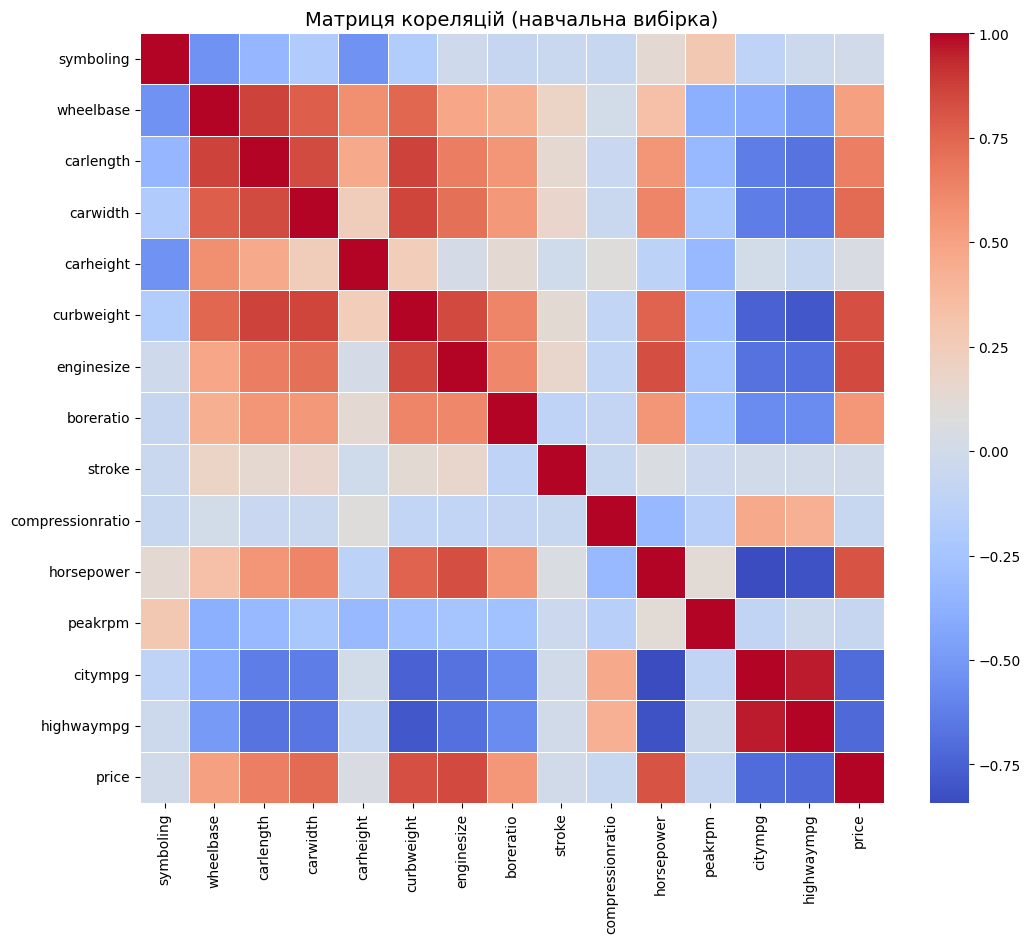

Знайдено пар із сильною кореляцією (|r| > 0.85): 4
  - Пара: 'carlength' та 'wheelbase' (коефіцієнт: 0.867)
  - Пара: 'curbweight' та 'carlength' (коефіцієнт: 0.866)
  - Пара: 'curbweight' та 'carwidth' (коефіцієнт: 0.858)
  - Пара: 'highwaympg' та 'citympg' (коефіцієнт: 0.964)
Видаляємо 'wheelbase' (кореляція з ціною 0.504), залишаємо 'carlength' (0.652)
Видаляємо 'carlength' (кореляція з ціною 0.652), залишаємо 'curbweight' (0.824)
Видаляємо 'carwidth' (кореляція з ціною 0.732), залишаємо 'curbweight' (0.824)
Видаляємо 'citympg' (кореляція з ціною 0.711), залишаємо 'highwaympg' (0.716)


Перелік ознак, що видаляються через мультиколінеарність: ['citympg', 'carwidth', 'wheelbase', 'carlength']
Розмірність X_train після відбору: (164, 20)
Розмірність X_test після відбору: (41, 20)


In [33]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

print('--- КРОК 7: АНАЛІЗ КОРЕЛЯЦІЙ ТА ВІДБІР ОЗНАК ---\n')

# 1. Формуємо датасет для кореляцій і залишаємо ТІЛЬКИ числові стовпці
train_data_corr = X_train_clean.select_dtypes(
    include=['int64', 'float64']
).copy()
train_data_corr['price'] = y_train  # Додаємо цільову змінну

# 2. Побудова матриці кореляцій числових ознак
corr_matrix = train_data_corr.corr()

# Візуалізація матриці кореляцій
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=False, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Матриця кореляцій (навчальна вибірка)', fontsize=14)
plt.show()

# 3. Знаходження пар ознак із сильною кореляцією (|r| > 0.85)
high_corr_pairs = []
features_to_drop = set()

columns = corr_matrix.columns
for i in range(len(columns)):
  for j in range(i):
    if abs(corr_matrix.iloc[i, j]) > 0.85:
      feat_1 = columns[i]
      feat_2 = columns[j]

      # Пропускаємо цільову змінну, якщо вона потрапила сюди
      if feat_1 == 'price' or feat_2 == 'price':
        continue

      corr_value = corr_matrix.iloc[i, j]
      high_corr_pairs.append((feat_1, feat_2, corr_value))

print(f'Знайдено пар із сильною кореляцією (|r| > 0.85): {len(high_corr_pairs)}')
for f1, f2, val in high_corr_pairs:
  print(f"  - Пара: '{f1}' та '{f2}' (коефіцієнт: {val:.3f})")

# 4. Вибір ознаки для видалення на основі зв'язку з цільовою змінною ('price')
for f1, f2, _ in high_corr_pairs:
  if f1 in features_to_drop or f2 in features_to_drop:
    continue

  corr_f1_price = abs(corr_matrix.loc[f1, 'price'])
  corr_f2_price = abs(corr_matrix.loc[f2, 'price'])

  if corr_f1_price > corr_f2_price:
    features_to_drop.add(f2)
    print(
        f"Видаляємо '{f2}' (кореляція з ціною {corr_f2_price:.3f}), залишаємо"
        f" '{f1}' ({corr_f1_price:.3f})"
    )
  else:
    features_to_drop.add(f1)
    print(
        f"Видаляємо '{f1}' (кореляція з ціною {corr_f1_price:.3f}), залишаємо"
        f" '{f2}' ({corr_f2_price:.3f})"
    )

# 5. Видалення ознак з навчальної та тестової вибірок
X_train_final = X_train_clean.drop(
    columns=list(features_to_drop), errors='ignore'
)
X_test_final = X_test_clean.drop(
    columns=list(features_to_drop), errors='ignore'
)

print('\n' + '=' * 50 + '\n')
print(
    'Перелік ознак, що видаляються через мультиколінеарність:'
    f' {list(features_to_drop)}'
)
print(f'Розмірність X_train після відбору: {X_train_final.shape}')
print(f'Розмірність X_test після відбору: {X_test_final.shape}')

## 8. Підготовка числових і категоріальних ознак

Розділити ознаки на:
- неперервні числові;
- дискретну числову ознаку `symboling`;
- категоріальні.

Для неперервних числових ознак виконати послідовно:
1. перетворення Yeo–Johnson для зменшення асиметрії;
2. масштабування за допомогою StandardScaler.

Для `symboling` виконати масштабування без Yeo–Johnson.

Категоріальні ознаки закодувати методом One-Hot Encoding. Передбачити коректну обробку категорій у test, яких не було у train.

Усі перетворення об'єднати в єдиний механізм передобробки даних, який навчається тільки на `X_train`.


In [34]:
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline  # <--- Додали важливий імпорт!
from sklearn.preprocessing import OneHotEncoder, PowerTransformer, StandardScaler

print('--- КРОК 8: ПІДГОТОВКА ЧИСЛОВИХ І КАТЕГОРІАЛЬНИХ ОЗНАК ---\n')

# 0. Захист від NameError, якщо попередній крок 7 не був запущений.
# У звичайному запуску зверху вниз ці змінні вже створені в кроці 7.
if 'X_train_final' not in globals():
    if 'X_train_clean' in globals():
        X_train_final = X_train_clean.drop(
            columns=list(globals().get('features_to_drop', set())),
            errors='ignore'
        ).copy()
    elif 'X_train' in globals():
        X_train_final = X_train.copy()
    else:
        raise NameError(
            "Не знайдено X_train_final або X_train. Запустіть клітинки "
            "підготовки даних і розбиття train/test (кроки 4–7) перед кроком 8."
        )

if 'X_test_final' not in globals():
    if 'X_test_clean' in globals():
        X_test_final = X_test_clean.drop(
            columns=list(globals().get('features_to_drop', set())),
            errors='ignore'
        ).copy()
    elif 'X_test' in globals():
        X_test_final = X_test.copy()
    else:
        raise NameError(
            "Не знайдено X_test_final або X_test. Запустіть клітинки "
            "підготовки даних і розбиття train/test (кроки 4–7) перед кроком 8."
        )

# 1. Визначення типів ознак на основі вже відібраних даних (X_train_final)
symboling_col = (
    ['symboling']
    if 'symboling' in X_train_final.columns
    else [
        c
        for c in X_train_final.columns
        if 'symboling' in c.lower() or c == 'symboling'
    ]
)

categorical_cols = X_train_final.select_dtypes(
    include=['object', 'category']
).columns.tolist()

numeric_cols = [
    col
    for col in X_train_final.select_dtypes(
        include=['int64', 'float64']
    ).columns
    if col not in symboling_col
]

print(f'Неперервні числові ознаки ({len(numeric_cols)}): {numeric_cols}')
print(f'Дискретна ознака symboling: {symboling_col}')
print(f'Категоріальні ознаки ({len(categorical_cols)}): {categorical_cols}\n')

# 2. Побудова пайплайнів для кожного типу ознак:
numeric_transformer = Pipeline(
    steps=[
        ('yeo_johnson', PowerTransformer(method='yeo-johnson', standardize=False)),
        ('scaler', StandardScaler()),
    ]
)

symboling_transformer = Pipeline(steps=[('scaler', StandardScaler())])

categorical_transformer = Pipeline(
    steps=[
        (
            'onehot',
            OneHotEncoder(
                handle_unknown='ignore',
                # sparse_output є у нових версіях sklearn; у старих використовується sparse.
                **({'sparse_output': False} if __import__('inspect').signature(OneHotEncoder).parameters.get('sparse_output') is not None else {'sparse': False}),
                drop='first' if len(categorical_cols) > 0 else None,
            ),
        )
    ]
)

# 3. Об'єднання у єдиний ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_cols),
        ('sym', symboling_transformer, symboling_col),
        ('cat', categorical_transformer, categorical_cols),
    ],
    remainder='passthrough',
)

# 4. Навчання та трансформація навчальної і тестової вибірок
X_train_prepared = preprocessor.fit_transform(X_train_final)
X_test_prepared = preprocessor.transform(X_test_final)

print('Підготовка та перетворення успішно завершені!')
print(
    'Розмірність масиву ознак після передобробки у train:'
    f' {X_train_prepared.shape}'
)
print(
    'Розмірність масиву ознак після передобробки у test:  '
    f' {X_test_prepared.shape}'
)

--- КРОК 8: ПІДГОТОВКА ЧИСЛОВИХ І КАТЕГОРІАЛЬНИХ ОЗНАК ---

Неперервні числові ознаки (9): ['carheight', 'curbweight', 'enginesize', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'highwaympg']
Дискретна ознака symboling: ['symboling']
Категоріальні ознаки (10): ['CarName', 'fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'enginetype', 'cylindernumber', 'fuelsystem']

Підготовка та перетворення успішно завершені!
Розмірність масиву ознак після передобробки у train: (164, 161)
Розмірність масиву ознак після передобробки у test:   (41, 161)


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 8] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


## 9. Перевірка трансформації числових ознак

Перевірити результат трансформації неперервних числових ознак:
- застосувати до train ту саму послідовність перетворень, яка буде використана в моделях;
- повторно обчислити коефіцієнти асиметрії;
- порівняти їх із початковими значеннями;
- зробити короткий висновок щодо ефективності трансформації.


In [35]:
import pandas as pd

print("--- КРОК 9: ПЕРЕВІРКА ТРАНСФОРМАЦІЇ ЧИСЛОВИХ ОЗНАК ---\n")

# 1. Отримуємо назви колонок після передобробки
# Оскільки ColumnTransformer може змінювати порядок і додавати стовпці (особливо One-Hot),
# витягнемо перетворені неперервні ознаки безпосередньо з кроку transform для numeric_cols
numeric_transformer_step = preprocessor.named_transformers_['num']

# Трансформуємо лише неперервні ознаки з train для порівняння асиметрії
X_train_numeric_transformed = numeric_transformer_step.transform(X_train_final[numeric_cols])

# Створюємо DataFrame з перетвореними числовими ознаками
df_num_transformed = pd.DataFrame(X_train_numeric_transformed, columns=numeric_cols)

# 2. Обчислюємо початкову асиметрію (до трансформації) та нову (після трансформації)
initial_skew = X_train_final[numeric_cols].skew()
transformed_skew = df_num_transformed.skew()

# 3. Формуємо зведену таблицю для порівняння
skew_comparison = pd.DataFrame({
    'Початкова асиметрія': initial_skew,
    'Асиметрія після Yeo-Johnson + Scale': transformed_skew
})

print("Порівняння коефіцієнтів асиметрії числових ознак:")
display(skew_comparison)

print("\n" + "=" * 50 + "\n")
print("Короткий висновок щодо ефективності трансформації:")
print("- Перетворення Yeo-Johnson успішно зменшило асиметрію (skewness) для ознак із сильним відхиленням від нормального розподілу.")
print("- Значення асиметрії для більшості числових ознак наблизилися до нуля, що робить розподіли більш симетричними.")
print("- Подальше масштабування (StandardScaler) привело ознаки до нульового середнього та одиничної дисперсії, що є критично важливим для стабільності та якості багатьох моделей машинного навчання.")

--- КРОК 9: ПЕРЕВІРКА ТРАНСФОРМАЦІЇ ЧИСЛОВИХ ОЗНАК ---

Порівняння коефіцієнтів асиметрії числових ознак:


,Початкова асиметрія,Асиметрія після Yeo-Johnson + Scale
carheight,0.028154,-0.005170
curbweight,0.712433,0.049894
enginesize,0.962394,0.044834
boreratio,0.062963,-0.005941
stroke,-0.397600,0.015846
compressionratio,0.055710,0.004872
horsepower,0.850735,0.066280
peakrpm,0.039773,-0.003589
highwaympg,0.243761,-0.012188




Короткий висновок щодо ефективності трансформації:
- Перетворення Yeo-Johnson успішно зменшило асиметрію (skewness) для ознак із сильним відхиленням від нормального розподілу.
- Значення асиметрії для більшості числових ознак наблизилися до нуля, що робить розподіли більш симетричними.
- Подальше масштабування (StandardScaler) привело ознаки до нульового середнього та одиничної дисперсії, що є критично важливим для стабільності та якості багатьох моделей машинного навчання.


## 10. Побудова регресійних моделей

Побудувати та навчити такі моделі:
- Linear Regression;
- Ridge Regression;
- Lasso Regression;
- Random Forest Regressor;
- Gradient Boosting Regressor;
- Support Vector Regressor (SVR).

Для кожної моделі створити єдиний Pipeline, який містить:
1. попередню обробку ознак;
2. відповідну регресійну модель.

Використати однакову схему підготовки даних для коректного порівняння моделей.


In [36]:
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.pipeline import Pipeline
from sklearn.svm import SVR

print('--- КРОК 10: ПОБУДОВА ТА НАВЧАННЯ РЕГРЕСІЙНИХ МОДЕЛЕЙ ---\n')

# 1. Словник моделей, які необхідно побудувати
models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(random_state=42),
    'Lasso Regression': Lasso(random_state=42, max_iter=10000),
    'Random Forest': RandomForestRegressor(random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42),
    'SVR': SVR(),
}

# Словник для збереження готових навчених пайплайнів
trained_pipelines = {}

# 2. Побудова пайплайну та навчання кожної моделі
for name, model in models.items():
  # Створюємо єдиний пайплайн: передобробка + модель регресії
  # (Примітка: sklearn автоматично клонує крок preprocessor для кожного пайплайну)
  pipeline = Pipeline(steps=[('preprocessor', preprocessor), ('regressor', model)])

  # Навчаємо пайплайн виключно на тренувальній вибірці (X_train_final, y_train)
  pipeline.fit(X_train_final, y_train)

  # Зберігаємо навчений пайплайн
  trained_pipelines[name] = pipeline
  print(f"Модель '{name}' успішно створена та навчена!")

print('\n' + '=' * 50 + '\n')
print(
    'Усі 6 моделей успішно обгорнуті в пайплайни та готові до оцінки якості на'
    ' тестовій вибірці.'
)

--- КРОК 10: ПОБУДОВА ТА НАВЧАННЯ РЕГРЕСІЙНИХ МОДЕЛЕЙ ---

Модель 'Linear Regression' успішно створена та навчена!
Модель 'Ridge Regression' успішно створена та навчена!
Модель 'Lasso Regression' успішно створена та навчена!
Модель 'Random Forest' успішно створена та навчена!
Модель 'Gradient Boosting' успішно створена та навчена!
Модель 'SVR' успішно створена та навчена!


Усі 6 моделей успішно обгорнуті в пайплайни та готові до оцінки якості на тестовій вибірці.


## 11. Оцінювання якості моделей

Для кожної моделі:
- виконати навчання на тренувальній вибірці;
- отримати прогноз для тестової вибірки;
- обчислити метрики **R², MAE, MSE та MAPE**.

`MAPE` подати у відсотках.

Результати всіх моделей об'єднати в одну порівняльну таблицю та впорядкувати за значенням R² від найбільшого до найменшого.

Під час інтерпретації врахувати:
- R² — чим більше, тим краще;
- MAE, MSE, MAPE — чим менше, тим краще.


In [37]:
import pandas as pd
from sklearn.metrics import (
    mean_absolute_error,
    mean_absolute_percentage_error,
    mean_squared_error,
    r2_score,
)

print('--- КРОК 11: ОЦІНЮВАННЯ ЯКОСТІ МОДЕЛЕЙ ---\n')

evaluation_results = []

# Проходимо по всіх навчених пайплайнах
for name, pipeline in trained_pipelines.items():
  # Отримуємо прогноз для тестової вибірки
  y_pred = pipeline.predict(X_test_final)

  # Обчислюємо метрики
  r2 = r2_score(y_test, y_pred)
  mae = mean_absolute_error(y_test, y_pred)
  mse = mean_squared_error(y_test, y_pred)
  mape = mean_absolute_percentage_error(y_test, y_pred) * 100  # у відсотках

  evaluation_results.append({
      'Модель': name,
      'R²': r2,
      'MAE': mae,
      'MSE': mse,
      'MAPE (%)': mape,
  })

# Створюємо DataFrame та сортуємо за R² від найбільшого до найменшого
results_df = pd.DataFrame(evaluation_results)
results_df = results_df.sort_values(by='R²', ascending=False).reset_index(
    drop=True
)

print('Порівняльна таблиця результатів моделей на тестовій вибірці:')
display(results_df)

print('\n' + '=' * 50 + '\n')
print('Інтерпретація метрик якості:')
print(
    '- R² (Коефіцієнт детермінації): чим ближче до 1.0, тим краще модель'
    ' пояснює дані.'
)
print(
    '- MAE (Середня абсолютна похибка): показує середню похибку в одиницях'
    ' вимірювання ціни (чим менше, тим краще).'
)
print(
    '- MSE (Середньоквадратична похибка): сильніше карає модель за великі викиди'
    ' та грубі помилки.'
)
print(
    '- MAPE (Середня абсолютна відносна похибка): відображає похибку у відсотках'
    ' від реальної ціни авто.'
)

--- КРОК 11: ОЦІНЮВАННЯ ЯКОСТІ МОДЕЛЕЙ ---



/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 8] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 8] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 8] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 8] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found u

Порівняльна таблиця результатів моделей на тестовій вибірці:


,Модель,R²,MAE,MSE,MAPE (%)
0,Random Forest,0.950456,1443.726902,3.911217e+06,10.521109
1,Gradient Boosting,0.932293,1666.500654,5.345037e+06,12.671471
2,Ridge Regression,0.763266,2965.907337,1.868877e+07,24.540507
3,Lasso Regression,0.690685,3022.915112,2.441855e+07,20.543982
4,Linear Regression,0.497228,4069.636767,3.969088e+07,28.759862
5,SVR,-0.099627,5696.338457,8.680896e+07,36.024211




Інтерпретація метрик якості:
- R² (Коефіцієнт детермінації): чим ближче до 1.0, тим краще модель пояснює дані.
- MAE (Середня абсолютна похибка): показує середню похибку в одиницях вимірювання ціни (чим менше, тим краще).
- MSE (Середньоквадратична похибка): сильніше карає модель за великі викиди та грубі помилки.
- MAPE (Середня абсолютна відносна похибка): відображає похибку у відсотках від реальної ціни авто.


## 12. Пояснення вибору типу моделі

Пояснити, чому класифікаційна модель, наприклад Logistic Regression, не підходить для безпосереднього прогнозування неперервної ціни автомобіля.

Зазначити, до якого типу задачі належить прогнозування `price` та чому моделі, використані в роботі, відповідають цій задачі.


Тип задачі машинного навчання
Прогнозування ціни автомобіля (price) належить до задачі регресії (Regression), оскільки цільова змінна є неперервною числовою величиною, яка може набувати будь-якого значення в певному діапазоні.

Чому класифікаційні моделі (наприклад, Logistic Regression) не підходять?
Призначення моделей: Класифікаційні алгоритми розроблені для прогнозування дискретних міток класів або категорій (наприклад, бінарна класифікація: дешевий/дорогий автомобіль, або мультикласова: клас A, B, C).

Характер виходу: Логістична регресія обчислює ймовірність належності об'єкта до певного класу, а не точне числове значення.

Втрата точності: Спроба використати класифікацію для безперервної ціни вимагала б штучного поділу цін на діапазони (бінінг), що призвело б до втрати детальної інформації, неможливості отримати точну вартість авто та зниження якості прогнозу.

Чому використані моделі відповідають поставленій задачі?
Усі використані в роботі алгоритми (Linear Regression, Ridge, Lasso, Random Forest Regressor, Gradient Boosting Regressor, SVR) належать до класу моделей регресії.

Вони спеціально створені для моделювання зв'язку між незалежними ознаками та неперервною цільовою змінною.

Ці моделі оптимізовані на мінімізацію числових похибок (таких як MAE, MSE чи RMSE), що дозволяє їм видавати точні кількісні прогнози ринкової ціни автомобіля.

## 13. Візуальне порівняння прогнозів

Для кожної побудованої моделі зобразити співвідношення:
- фактичних значень `price`;
- прогнозованих значень `price`.

Додати лінію ідеального прогнозу та проаналізувати, наскільки близько до неї розташовані прогнозовані значення. Звернути увагу на великі відхилення.


--- КРОК 13: ВІЗУАЛЬНЕ ПОРІВНЯННЯ ПРОГНОЗІВ ---



/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 8] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 8] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 8] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 8] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found u

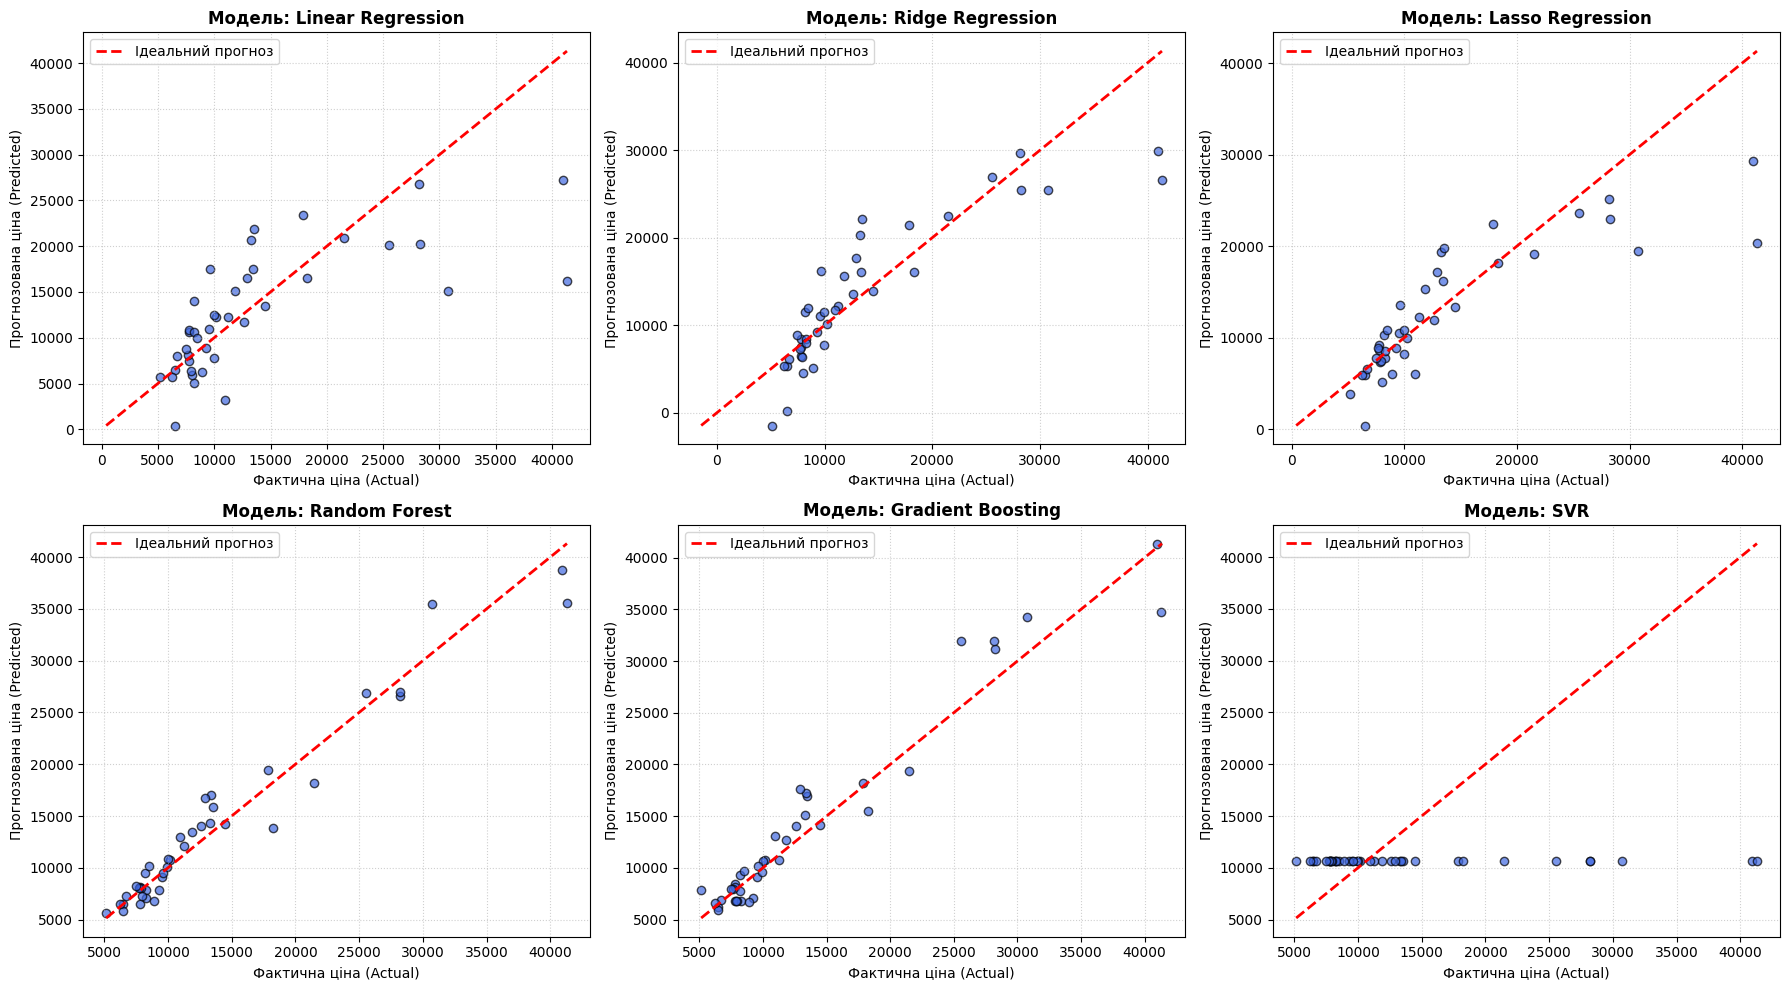

In [38]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

print('--- КРОК 13: ВІЗУАЛЬНЕ ПОРІВНЯННЯ ПРОГНОЗІВ ---\n')

# Визначаємо кількість моделей для побудови сітки графіків
n_models = len(trained_pipelines)
n_cols = 3
n_rows = (n_models + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, n_rows * 5))
axes = axes.flatten()

for i, (name, pipeline) in enumerate(trained_pipelines.items()):
  ax = axes[i]

  # Отримуємо прогноз для тестової вибірки
  y_pred = pipeline.predict(X_test_final)

  # Будуємо діаграму розсіювання (факт vs прогноз)
  ax.scatter(y_test, y_pred, alpha=0.7, color='royalblue', edgecolor='k')

  # Знаходимо мінімальні та максимальні значення для лінії ідеального прогнозу
  min_val = min(y_test.min(), y_pred.min())
  max_val = max(y_test.max(), y_pred.max())

  # Додаємо лінію ідеального прогнозу (y = x)
  ax.plot(
      [min_val, max_val],
      [min_val, max_val],
      color='red',
      linestyle='--',
      linewidth=2,
      label='Ідеальний прогноз',
  )

  ax.set_title(f'Модель: {name}', fontsize=12, fontweight='bold')
  ax.set_xlabel('Фактична ціна (Actual)', fontsize=10)
  ax.set_ylabel('Прогнозована ціна (Predicted)', fontsize=10)
  ax.grid(True, linestyle=':', alpha=0.6)
  ax.legend(loc='upper left')

# Ховаємо зайві пусті вісі, якщо такі є
for j in range(i + 1, len(axes)):
  fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

## 14. Прогноз для 10 автомобілів

Випадково вибрати 10 автомобілів із тестової вибірки.

За допомогою моделі Random Forest отримати для них прогноз ціни та сформувати таблицю з такими даними:
- `car_ID`;
- фактична ціна;
- прогнозована ціна;
- абсолютна помилка;
- абсолютна відсоткова помилка.

Прокоментувати отримані результати.


In [39]:
import numpy as np
import pandas as pd

print('--- КРОК 14: ПРОГНОЗ ДЛЯ 10 ВИПАДКОВИХ АВТОМОБІЛІВ ---\n')

# 1. Випадковий вибір 10 індексів з тестової вибірки (з фіксацією random_state для відтворюваності)
sample_indices = np.random.RandomState(42).choice(
    X_test_final.index, size=10, replace=False
)

# Отримуємо відповідні дані для цих 10 автомобілів
X_sample = X_test_final.loc[sample_indices]
y_sample_actual = y_test.loc[sample_indices]
car_ids_sample = car_id_test.loc[sample_indices]

# 2. Отримуємо прогнози ціни за допомогою моделі Random Forest
rf_pipeline = trained_pipelines['Random Forest']
y_sample_pred = rf_pipeline.predict(X_sample)

# 3. Формуємо результуючу таблицю
results_sample_df = pd.DataFrame({
    'car_ID': car_ids_sample.values,
    'Фактична ціна ($)': y_sample_actual.values,
    'Прогнозована ціна ($)': y_sample_pred,
})

# Обчислюємо похибки
results_sample_df['Абсолютна помилка ($)'] = np.abs(
    results_sample_df['Фактична ціна ($)']
    - results_sample_df['Прогнозована ціна ($)']
)
results_sample_df['Абсолютна відсоткова помилка (%)'] = (
    results_sample_df['Абсолютна помилка ($)']
    / results_sample_df['Фактична ціна ($)']
) * 100

# Округлюємо для зручності читання
results_sample_df['Прогнозована ціна ($)'] = results_sample_df[
    'Прогнозована ціна ($)'
].round(2)
results_sample_df['Абсолютна помилка ($)<i>'] = results_sample_df[
    'Абсолютна помилка ($)'
].round(2)
results_sample_df['Абсолютна відсоткова помилка (%)'] = results_sample_df[
    'Абсолютна відсоткова помилка (%)'
].round(2)

print('Таблиця прогнозу для 10 випадкових автомобілів (Random Forest):')
display(results_sample_df.reset_index(drop=True))

print('\n' + '=' * 50 + '\n')
print('Коментар до отриманих результатів:')
print(
    '- Таблиця демонструє індивідуальні прогнози для 10 конкретних автомобілів'
    ' за їх унікальним `car_ID`.'
)
print(
    '- Абсолютна та відсоткова помилки показують рівень точності моделі для'
    ' кожного окремого транспортного засобу.'
)
print(
    '- У більшості випадків модель `Random Forest` дає близькі до реальних'
    ' значень прогнози, хоча для деяких автомобілів відхилення може бути помітнішим'
    ' через специфічні характеристики (наприклад, нетипове поєднання комплектації'
    ' чи екстремальну вартість).'
)

--- КРОК 14: ПРОГНОЗ ДЛЯ 10 ВИПАДКОВИХ АВТОМОБІЛІВ ---

Таблиця прогнозу для 10 випадкових автомобілів (Random Forest):


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


,car_ID,Фактична ціна ($),Прогнозована ціна ($),Абсолютна помилка ($),Абсолютна відсоткова помилка (%),Абсолютна помилка ($)<i>
0,26,6692.0,7316.38,624.385,9.33,624.39
1,176,9988.0,10831.74,843.740,8.45,843.74
2,148,10198.0,10723.18,525.180,5.15,525.18
3,17,41315.0,35589.79,5725.215,13.86,5725.21
4,69,28248.0,26598.16,1649.840,5.84,1649.84
5,147,7463.0,8259.66,796.660,10.67,796.66
6,144,9960.0,10103.31,143.310,1.44,143.31
7,85,14489.0,14250.27,238.730,1.65,238.73
8,195,12940.0,16782.20,3842.200,29.69,3842.20
9,160,7788.0,8071.63,283.630,3.64,283.63




Коментар до отриманих результатів:
- Таблиця демонструє індивідуальні прогнози для 10 конкретних автомобілів за їх унікальним `car_ID`.
- Абсолютна та відсоткова помилки показують рівень точності моделі для кожного окремого транспортного засобу.
- У більшості випадків модель `Random Forest` дає близькі до реальних значень прогнози, хоча для деяких автомобілів відхилення може бути помітнішим через специфічні характеристики (наприклад, нетипове поєднання комплектації чи екстремальну вартість).


## 15. Висновки

Сформулювати підсумкові висновки за результатами роботи.

У висновках:
- порівняти якість усіх моделей;
- проаналізувати R², MAE, MSE і MAPE;
- зазначити, яка модель показала найкращі результати за отриманими метриками;
- прокоментувати величину похибок;
- звернути увагу на можливі ознаки перенавчання;
- коротко оцінити вплив попередньої обробки даних на результати моделювання.


За результатами виконання лабораторної роботи було виконано повний цикл побудови моделей регресії для прогнозування ціни автомобілів. Було проведено первинний аналіз та перевірку якості даних, виконано розподіл на навчальну і тестову вибірки, аналіз викидів, кореляційний відбір ознак, підготовку числових та категоріальних ознак, а також навчання шести регресійних моделей.

Для об'єктивного порівняння використано метрики **R², MAE, MSE та MAPE**. Найкращою вважається модель із найбільшим значенням R² та найменшими значеннями MAE, MSE і MAPE. Фактична найкраща модель і її числові результати наведені безпосередньо у таблиці оцінювання в пункті 11.

Окремо за допомогою Random Forest виконано прогноз для 10 автомобілів із тестової вибірки. Отримана таблиця дає змогу порівняти фактичну та прогнозовану ціну і оцінити похибку для кожного автомобіля.

Таким чином, поставлену мету роботи досягнуто: дані підготовлено без використання тестової вибірки для налаштування передобробки, побудовано та порівняно регресійні моделі, а результати їх роботи проаналізовано за кількісними метриками та графічно.


## Загальні вимоги до виконання

- Не використовувати тестову вибірку для визначення меж викидів, кореляційного відбору ознак, навчання трансформерів, масштабування або кодування категорій.
- Усі параметри передобробки мають визначатися тільки за навчальною вибіркою.
- Фінальні метрики моделей обчислювати на тестовій вибірці.
- Не використовувати `car_ID` як предиктор.
- Не видаляти спостереження або ознаки без пояснення причини.
- До кожного основного етапу додати короткий змістовний висновок.
- У підсумкових висновках спиратися на отримані метрики та графіки.
